In [3]:
import pandas as pd

df = pd.read_csv("songs_modeling_ready.csv")

yearly = pd.read_csv("yearly_summary.csv")
decade = pd.read_csv("decade_summary.csv")
language = pd.read_csv("language_summary.csv")
quality = pd.read_csv("data_quality_summary.csv")

print("Main dataset:", df.shape)
print("Yearly summary:", yearly.shape)
print("Decade summary:", decade.shape)

display(df[["Year", "Rank", "Song Title", "Word Count New", "Unique Word Count New", "Lexical Diversity", "Language"]].head())

Main dataset: (6224, 36)
Yearly summary: (65, 10)
Decade summary: (8, 10)


,Year,Rank,Song Title,Word Count New,Unique Word Count New,Lexical Diversity,Language
0,1959,1,The Battle Of New Orleans,434,144,0.331797,en
1,1959,2,Mack The Knife,224,128,0.571429,en
2,1959,3,Personality,215,48,0.223256,en
3,1959,4,Venus,166,69,0.415663,en
4,1959,5,Lonely Boy,140,60,0.428571,en


**1.EDA**

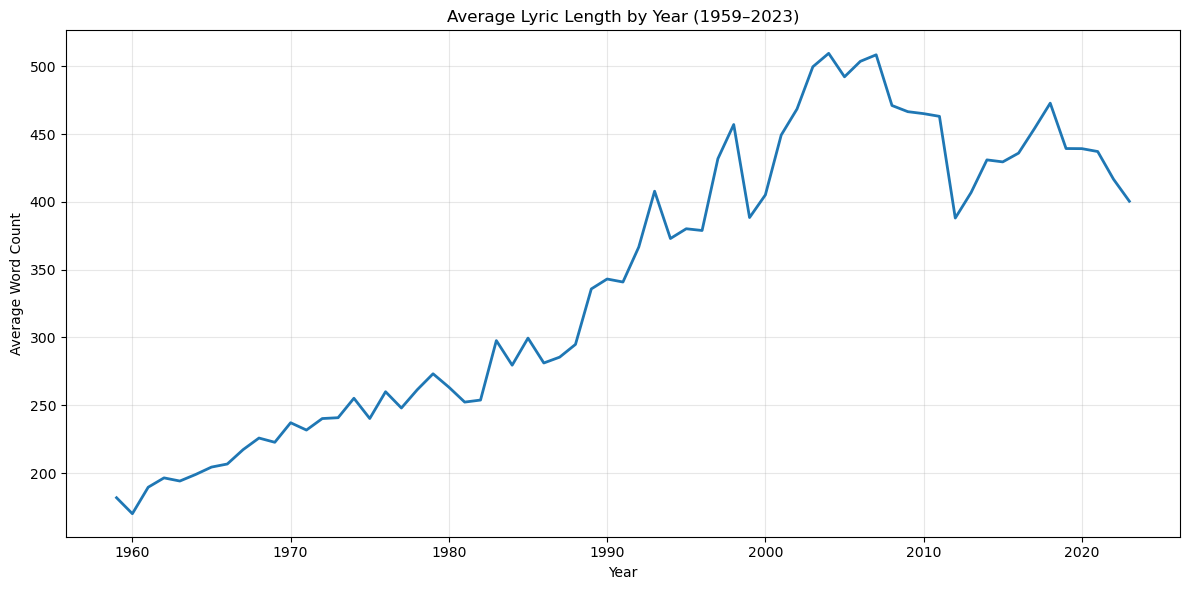

In [2]:
import matplotlib.pyplot as plt

yearly = yearly.sort_values("Year")

plt.figure(figsize=(12, 6))

plt.plot(yearly["Year"], yearly["Average_Word_Count"], linewidth=2)

plt.xlabel("Year")
plt.ylabel("Average Word Count")
plt.title("Average Lyric Length by Year (1959–2023)")
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig("EDA_01_Average_Lyric_Length.png", dpi=300)

plt.show()

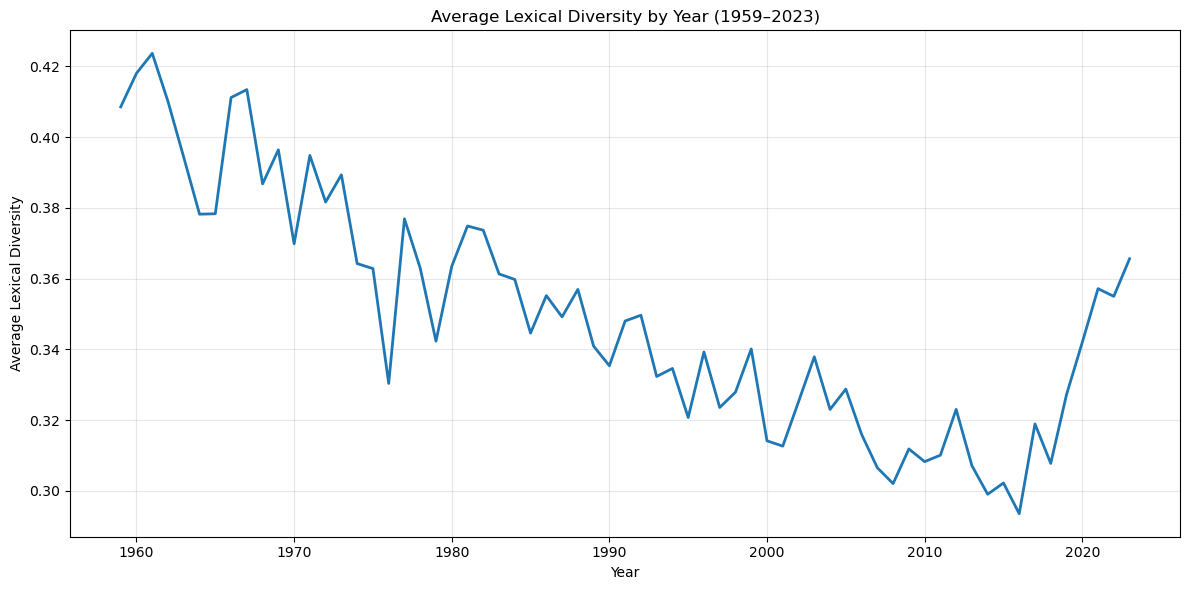

In [3]:
plt.figure(figsize=(12, 6))

plt.plot(yearly["Year"], yearly["Average_Lexical_Diversity"], linewidth=2)

plt.xlabel("Year")
plt.ylabel("Average Lexical Diversity")
plt.title("Average Lexical Diversity by Year (1959–2023)")
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig("EDA_02_Lexical_Diversity.png", dpi=300)

plt.show()

             count        mean  median
Rank Group                            
Top 10         624  351.245192   322.5
Rank 11-50    2495  348.943086   308.0
Rank 51-100   3105  337.676973   300.0


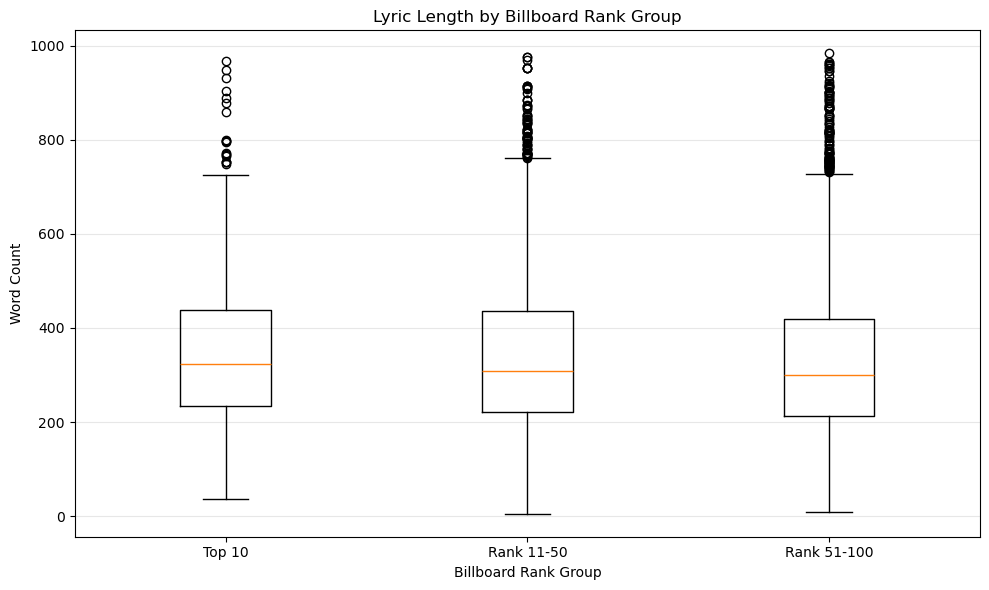

In [5]:
df["Rank Group"] = pd.cut(df["Rank"], bins=[0, 10, 50, 100], labels=["Top 10", "Rank 11-50", "Rank 51-100"])

rank_summary = df.groupby("Rank Group", observed=True)["Word Count New"].agg(["count", "mean", "median"])

print(rank_summary)

groups = [df.loc[df["Rank Group"] == group, "Word Count New"]
    for group in ["Top 10", "Rank 11-50", "Rank 51-100"]]

plt.figure(figsize=(10, 6))

plt.boxplot(groups, labels=["Top 10", "Rank 11-50", "Rank 51-100"])

plt.xlabel("Billboard Rank Group")
plt.ylabel("Word Count")
plt.title("Lyric Length by Billboard Rank Group")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("EDA_03_Lyric_Length_by_Rank.png", dpi=300)
plt.show()

**2.LDA**

In [6]:
print("Text-related columns:")
print([
    col for col in df.columns
    if "lyric" in col.lower()
    or "language" in col.lower()
    or "translat" in col.lower()])

print("\nLanguage distribution:")
print(df["Language"].value_counts(dropna=False).head(10))

for i in range(3):
    print("\nSong:", df.loc[i, "Song Title"])
    print("Language:", df.loc[i, "Language"])
    print("Clean Lyrics:")
    print(str(df.loc[i, "Clean Lyrics"])[:300])
    print("-" * 50)

Text-related columns:
['Lyrics', 'Lyrics Missing', 'Clean Lyrics', 'Language', 'Language Confidence', 'Language Reliable', 'Translation Required', 'Suspected Non-Lyrics']

Language distribution:
Language
en         6099
es           38
unknown      15
pt           10
so           10
ru           10
de            7
tr            7
tl            6
id            5
Name: count, dtype: int64

Song: The Battle Of New Orleans
Language: en
Clean Lyrics:
in 1814 we took a little trip along with colonel jackson down the mighty mississip we took a little bacon and we took a little beans and we caught the bloody british in a town near new orleans we fired our guns and the british kept a-comin' there wasn't nigh as many as there was a while ago we fired
--------------------------------------------------

Song: Mack The Knife
Language: en
Clean Lyrics:
oh the shark babe has such teeth dear and he shows them pearly white just a jackknife has old macheath babe and he keeps it out of sight you know whe

In [4]:
from sklearn.feature_extraction.text import CountVectorizer

lda_df = df[(df["Language"] == "en") & (df["Language Reliable"] == True)].copy()

print("Songs for initial LDA:", len(lda_df))

vectorizer = CountVectorizer(stop_words="english", min_df=10, max_df=0.9, token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")

dtm = vectorizer.fit_transform(lda_df["Clean Lyrics"])

print("Document-Term Matrix shape:", dtm.shape)

word_counts = dtm.sum(axis=0).A1
words = vectorizer.get_feature_names_out()

word_frequency = pd.DataFrame({"Word": words, "Frequency": word_counts})

word_frequency = word_frequency.sort_values("Frequency", ascending=False)

display(word_frequency.head(20))

Songs for initial LDA: 5913
Document-Term Matrix shape: (5913, 4027)


,Word,Frequency
2080,love,19640
2386,oh,17451
972,don,15420
1899,know,14439
2004,like,14286
4005,yeah,12887
138,baby,12829
1845,just,12222
1457,got,10823
2037,ll,9445


In [5]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

custom_stopwords = ["oh", "ooh", "yeah", "ah", "uh", "huh", "hey", "la", "na", "whoa", "woah", "don", "ll", "ve", "re"]

all_stopwords = list(ENGLISH_STOP_WORDS.union(custom_stopwords))

vectorizer = CountVectorizer(stop_words=all_stopwords, min_df=10, max_df=0.9, token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")

dtm = vectorizer.fit_transform(lda_df["Clean Lyrics"])

print("Updated DTM shape:", dtm.shape)

word_counts = dtm.sum(axis=0).A1
words = vectorizer.get_feature_names_out()

word_frequency = pd.DataFrame({"Word": words, "Frequency": word_counts})

word_frequency = word_frequency.sort_values("Frequency", ascending=False)

display(word_frequency.head(20))

Updated DTM shape: (5913, 4013)


,Word,Frequency
2074,love,19640
1895,know,14439
1999,like,14286
137,baby,12829
1841,just,12222
1455,got,10823
1975,let,8522
3816,want,7170
3589,time,6702
498,cause,6663


In [6]:
from sklearn.decomposition import LatentDirichletAllocation

all_stopwords = list(set(all_stopwords) | {"ain"})

vectorizer = CountVectorizer(stop_words=all_stopwords, min_df=10, max_df=0.9, token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")

dtm = vectorizer.fit_transform(lda_df["Clean Lyrics"])

lda_model = LatentDirichletAllocation(n_components=5, random_state=42, max_iter=10, learning_method="batch")

lda_topics = lda_model.fit_transform(dtm)

feature_names = vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(lda_model.components_):
    top_words = [feature_names[i]
        for i in topic.argsort()[-12:][::-1]]

    print(f"Topic {topic_idx + 1}:")
    print(", ".join(top_words))
    print()

Topic 1:
let, wanna, da, little, want, come, love, know, just, baby, say, make

Topic 2:
like, got, money, shit, em, nigga, know, just, bitch, fuck, niggas, cause

Topic 3:
just, know, like, said, away, day, home, time, man, say, got, world

Topic 4:
like, baby, know, got, girl, just, right, make, let, gonna, wanna, cause

Topic 5:
love, baby, know, just, time, heart, want, night, feel, way, say, come



In [10]:
import numpy as np

for topic_idx in range(5):
    print(f"\n========== Topic {topic_idx + 1} ==========")

    top_song_indices = np.argsort(lda_topics[:, topic_idx] )[-5:][::-1]

    for idx in top_song_indices:
        song = lda_df.iloc[idx]

        print(
            f"Song: {song['Song Title']} | "
            f"Year: {song['Year']} | "
            f"Rank: {song['Rank']} | "
            f"Topic Probability: {lda_topics[idx, topic_idx]:.3f}")


========== Topic 1 ==========
Song: Rock the Boat | Year: 2002 | Rank: 85 | Topic Probability: 0.997
Song: Ex-Factor | Year: 1999 | Rank: 62 | Topic Probability: 0.996
Song: You Make Me Wanna... | Year: 1998 | Rank: 15 | Topic Probability: 0.996
Song: You Make Me Wanna... | Year: 1997 | Rank: 14 | Topic Probability: 0.996
Song: Surfin' Bird | Year: 1964 | Rank: 75 | Topic Probability: 0.995

========== Topic 2 ==========
Song: Bartier Cardi | Year: 2018 | Rank: 61 | Topic Probability: 0.998
Song: Thot Shit | Year: 2021 | Rank: 71 | Topic Probability: 0.998
Song: Check Yo Self | Year: 1993 | Rank: 86 | Topic Probability: 0.998
Song: No Limit | Year: 2018 | Rank: 30 | Topic Probability: 0.998
Song: 2 Phones | Year: 2016 | Rank: 57 | Topic Probability: 0.998

========== Topic 3 ==========
Song: Oh Happy Day | Year: 1969 | Rank: 93 | Topic Probability: 0.997
Song: Cotton Eye Joe | Year: 1995 | Rank: 93 | Topic Probability: 0.996
Song: Pumped Up Kicks | Year: 2011 | Rank: 13 | Topic Probab

In [7]:
from collections import Counter

topic_words = []

for topic in lda_model.components_:
    top_indices = topic.argsort()[-12:][::-1]
    words = feature_names[top_indices]
    topic_words.append(list(words))

word_counter = Counter(
    word
    for words in topic_words
    for word in words)

shared_words = {
    word: count
    for word, count in word_counter.items()
    if count >= 2}

print("Words shared across topics:")
print(shared_words)

total_words = 5 * 12
unique_words = len(word_counter)

topic_diversity = unique_words / total_words

print("\nTopic Diversity:", round(topic_diversity, 3))

Words shared across topics:
{'let': 2, 'wanna': 2, 'want': 2, 'come': 2, 'love': 2, 'know': 5, 'just': 5, 'baby': 3, 'say': 3, 'make': 2, 'like': 3, 'got': 3, 'cause': 2, 'time': 2}

Topic Diversity: 0.6


In [8]:
baseline_diversity = topic_diversity

refined_stopwords = list(set(all_stopwords) | {"know", "just"})

vectorizer_refined = CountVectorizer(
    stop_words=refined_stopwords,
    min_df=10,
    max_df=0.9,
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")

dtm_refined = vectorizer_refined.fit_transform(
    lda_df["Clean Lyrics"])

lda_refined = LatentDirichletAllocation(
    n_components=5,
    random_state=42,
    max_iter=10,
    learning_method="batch")

lda_topics_refined = lda_refined.fit_transform(dtm_refined)

feature_names_refined = vectorizer_refined.get_feature_names_out()

refined_topic_words = []

for topic_idx, topic in enumerate(lda_refined.components_):
    top_indices = topic.argsort()[-12:][::-1]
    top_words = feature_names_refined[top_indices]

    refined_topic_words.append(list(top_words))

    print(f"Topic {topic_idx + 1}:")
    print(", ".join(top_words))
    print()

unique_words = len(set(
    word
    for words in refined_topic_words
    for word in words))

refined_diversity = unique_words / (5 * 12)

print("Original Topic Diversity:", round(baseline_diversity, 3))
print("Refined Topic Diversity:", round(refined_diversity, 3))

Topic 1:
night, little, dance, come, away, doo, let, home, light, like, eyes, woman

Topic 2:
baby, let, wanna, girl, like, got, come, love, make, want, right, cause

Topic 3:
love, time, like, way, say, life, heart, cause, feel, tell, day, make

Topic 4:
want, got, love, heart, hold, stop, let, won, everybody, need, sweet, shake

Topic 5:
like, got, em, shit, nigga, money, bitch, cause, fuck, gon, niggas, big

Original Topic Diversity: 0.6
Refined Topic Diversity: 0.75


In [13]:
import numpy as np

for topic_idx in range(5):
    print(f"\n========== Refined Topic {topic_idx + 1} ==========")

    top_song_indices = np.argsort(
        lda_topics_refined[:, topic_idx]
    )[-5:][::-1]

    for idx in top_song_indices:
        song = lda_df.iloc[idx]

        print(
            f"Song: {song['Song Title']} | "
            f"Year: {song['Year']} | "
            f"Rank: {song['Rank']} | "
            f"Probability: {lda_topics_refined[idx, topic_idx]:.3f}")


========== Refined Topic 1 ==========
Song: Cotton Eye Joe | Year: 1995 | Rank: 93 | Probability: 0.996
Song: Come Sail Away | Year: 1978 | Rank: 56 | Probability: 0.995
Song: Into The Night | Year: 2008 | Rank: 98 | Probability: 0.995
Song: Rocky Mountain High | Year: 1973 | Rank: 29 | Probability: 0.995
Song: Wildest Dreams | Year: 2015 | Rank: 57 | Probability: 0.994

========== Refined Topic 2 ==========
Song: Dude | Year: 2004 | Rank: 85 | Probability: 0.998
Song: Shy Guy | Year: 1995 | Rank: 43 | Probability: 0.997
Song: Knockin' Da Boots | Year: 1993 | Rank: 14 | Probability: 0.997
Song: Get Down, Get Down (Get On The Floor) | Year: 1975 | Rank: 76 | Probability: 0.997
Song: What'd I Say | Year: 1959 | Rank: 50 | Probability: 0.997

========== Refined Topic 3 ==========
Song: Doesn't Really Matter | Year: 2000 | Rank: 18 | Probability: 0.997
Song: We Are The World | Year: 1985 | Rank: 20 | Probability: 0.997
Song: The Promise Of A New Day | Year: 1991 | Rank: 41 | Probability: 

In [9]:
import importlib.util

if importlib.util.find_spec("spacy") is None:
    print("spaCy is not installed.")
else:
    import spacy

    print("spaCy version:", spacy.__version__)

    if spacy.util.is_package("en_core_web_sm"):
        print("English model is available.")

        nlp = spacy.load("en_core_web_sm")

        doc = nlp("She was dancing and singing songs.")

        for token in doc:
            print(token.text, "->", token.lemma_)
    else:
        print("English model is not installed.")

spaCy version: 3.8.18
English model is available.
She -> she
was -> be
dancing -> dance
and -> and
singing -> sing
songs -> song
. -> .


In [10]:
lemmatized_lyrics = []

with nlp.select_pipes(disable=["parser", "ner"]):

    for doc in nlp.pipe(
        lda_df["Clean Lyrics"].fillna("").astype(str),
        batch_size=64):
       
        words = [
            token.lemma_.lower()
            for token in doc
            if token.is_alpha]

        lemmatized_lyrics.append(" ".join(words))

lda_df["LDA Lyrics"] = lemmatized_lyrics

print("Total processed songs:", len(lda_df))

for i in range(3):
    print("\nSong:", lda_df.iloc[i]["Song Title"])
    print("Before:")
    print(lda_df.iloc[i]["Clean Lyrics"][:200])

    print("\nAfter:")
    print(lda_df.iloc[i]["LDA Lyrics"][:200])
    print("-" * 50)

Total processed songs: 5913

Song: The Battle Of New Orleans
Before:
in 1814 we took a little trip along with colonel jackson down the mighty mississip we took a little bacon and we took a little beans and we caught the bloody british in a town near new orleans we fire

After:
in we take a little trip along with colonel jackson down the mighty mississip we take a little bacon and we take a little bean and we catch the bloody british in a town near new orleans we fire our gu
--------------------------------------------------

Song: Mack The Knife
Before:
oh the shark babe has such teeth dear and he shows them pearly white just a jackknife has old macheath babe and he keeps it out of sight you know when that shark bites with his teeth babe scarlet bill

After:
oh the shark babe have such tooth dear and he show they pearly white just a jackknife have old macheath babe and he keep it out of sight you know when that shark bite with his tooth babe scarlet billo
------------------------------

In [11]:
vectorizer_lemma = CountVectorizer(
    stop_words=refined_stopwords,
    min_df=10,
    max_df=0.9,
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")

dtm_lemma = vectorizer_lemma.fit_transform(lda_df["LDA Lyrics"])

print("Lemmatized DTM shape:", dtm_lemma.shape)

lda_lemma = LatentDirichletAllocation(
    n_components=5,
    random_state=42,
    max_iter=10,
    learning_method="batch")

lda_topics_lemma = lda_lemma.fit_transform(dtm_lemma)

feature_names_lemma = vectorizer_lemma.get_feature_names_out()

lemma_topic_words = []

for topic_idx, topic in enumerate(lda_lemma.components_):
    top_indices = topic.argsort()[-12:][::-1]
    top_words = feature_names_lemma[top_indices]

    lemma_topic_words.append(list(top_words))

    print(f"\nTopic {topic_idx + 1}:")
    print(", ".join(top_words))

unique_words = len(set(
    word
    for words in lemma_topic_words
    for word in words))

lemma_diversity = unique_words / (5 * 12)

print("\n--- Model Comparison ---")
print("Baseline Diversity:", round(topic_diversity, 3))
print("Refined Diversity:", round(refined_diversity, 3))
print("Lemmatized Diversity:", round(lemma_diversity, 3))

Lemmatized DTM shape: (5913, 3255)

Topic 1:
like, girl, ya, bitch, shit, money, nigga, say, fuck, let, wanna, make

Topic 2:
like, boy, bad, make, night, watch, girl, wanna, run, feel, want, break

Topic 3:
baby, come, say, time, man, good, girl, away, home, think, tell, make

Topic 4:
want, baby, love, let, say, make, wanna, feel, time, need, tell, right

Topic 5:
love, heart, way, day, like, eye, dream, life, fall, make, sweet, night

--- Model Comparison ---
Baseline Diversity: 0.6
Refined Diversity: 0.75
Lemmatized Diversity: 0.667


In [17]:
import importlib.util

if importlib.util.find_spec("gensim") is None:
    print("Gensim is not installed.")
else:
    try:
        import gensim
        from gensim.models import CoherenceModel
        from gensim.corpora import Dictionary

        print("Gensim version:", gensim.__version__)
        print("CoherenceModel is available.")
        print("Dictionary is available.")

    except Exception as e:
        print("Gensim import failed:")
        print(type(e).__name__, str(e))

Gensim import failed:
ImportError cannot import name 'triu' from 'scipy.linalg' (C:\Users\11854\anaconda3\Lib\site-packages\scipy\linalg\__init__.py)


In [18]:
import numpy as np
import scipy
import scipy.linalg

scipy.linalg.triu = np.triu

import gensim
from gensim.models import CoherenceModel
from gensim.corpora import Dictionary

print("SciPy version:", scipy.__version__)
print("Gensim version:", gensim.__version__)
print("CoherenceModel is available.")
print("Dictionary is available.")

RuntimeError: Compiled extensions are unavailable. If you've installed from a package, ask the package maintainer to include compiled extensions. If you're building Gensim from source yourself, install Cython and a C compiler, and then run `python setup.py build_ext --inplace` to retry. 

In [1]:
import numpy as np
import scipy.linalg

scipy.linalg.triu = np.triu

import gensim
from gensim.models import CoherenceModel
from gensim.corpora import Dictionary

print("Gensim version:", gensim.__version__)
print("Gensim import successful!")

Gensim version: 4.3.2
Gensim import successful!


In [12]:
required_variables = [
    "lda_df",
    "lda_model",
    "lda_refined",
    "lda_lemma",
    "vectorizer",
    "vectorizer_refined",
    "vectorizer_lemma",
    "topic_words",
    "refined_topic_words",
    "lemma_topic_words"]

for name in required_variables:
    print(name, ":", "OK" if name in globals() else "Missing")

lda_df : OK
lda_model : OK
lda_refined : OK
lda_lemma : OK
vectorizer : OK
vectorizer_refined : OK
vectorizer_lemma : OK
topic_words : OK
refined_topic_words : OK
lemma_topic_words : OK


In [13]:
from gensim.models import CoherenceModel
from gensim.corpora import Dictionary

eval_df = lda_df.sample(
    n=min(1000, len(lda_df)),
    random_state=42)

analyzer = vectorizer_refined.build_analyzer()

texts_refined = [
    analyzer(text)
    for text in eval_df["Clean Lyrics"].fillna("")]

dictionary_refined = Dictionary(texts_refined)

topics_refined = [
    list(words[:10])
    for words in refined_topic_words]

coherence_model = CoherenceModel(
    topics=topics_refined,
    texts=texts_refined,
    dictionary=dictionary_refined,
    coherence="c_v",
    topn=10,
    processes=1)

coherence_refined = coherence_model.get_coherence()

print("Refined LDA C_v Coherence:", round(coherence_refined, 4))

Refined LDA C_v Coherence: 0.4401


In [14]:
analyzer_baseline = vectorizer.build_analyzer()

texts_baseline = [
    analyzer_baseline(text)
    for text in eval_df["Clean Lyrics"].fillna("")]

dictionary_baseline = Dictionary(texts_baseline)

coherence_baseline = CoherenceModel(
    topics=[list(words[:10]) for words in topic_words],
    texts=texts_baseline,
    dictionary=dictionary_baseline,
    coherence="c_v",
    topn=10,
    processes=1
).get_coherence()

analyzer_lemma = vectorizer_lemma.build_analyzer()

texts_lemma = [
    analyzer_lemma(text)
    for text in eval_df["LDA Lyrics"].fillna("")]

dictionary_lemma = Dictionary(texts_lemma)

coherence_lemma = CoherenceModel(
    topics=[list(words[:10]) for words in lemma_topic_words],
    texts=texts_lemma,
    dictionary=dictionary_lemma,
    coherence="c_v",
    topn=10,
    processes=1
).get_coherence()

comparison = pd.DataFrame({
    "Model": ["Baseline", "Refined", "Lemmatized"],
    "Topic Diversity": [
        topic_diversity,
        refined_diversity,
        lemma_diversity],
    "C_v Coherence": [
        coherence_baseline,
        coherence_refined,
        coherence_lemma]})

print("LDA Model Comparison:")
display(comparison.round(4))

LDA Model Comparison:


,Model,Topic Diversity,C_v Coherence
0,Baseline,0.6000,0.4445
1,Refined,0.7500,0.4401
2,Lemmatized,0.6667,0.4391


In [15]:
lda_8 = LatentDirichletAllocation(
    n_components=8,
    random_state=42,
    max_iter=10,
    learning_method="batch")

lda_topics_8 = lda_8.fit_transform(dtm_refined)

feature_names_8 = vectorizer_refined.get_feature_names_out()

topic_words_8 = []

for topic_idx, topic in enumerate(lda_8.components_):
    top_indices = topic.argsort()[-12:][::-1]
    top_words = list(feature_names_8[top_indices])

    topic_words_8.append(top_words)

    print(f"Topic {topic_idx + 1}:")
    print(", ".join(top_words))
    print()

unique_words_8 = len(set(
    word
    for words in topic_words_8
    for word in words))

diversity_8 = unique_words_8 / (8 * 12)

coherence_8 = CoherenceModel(
    topics=[words[:10] for words in topic_words_8],
    texts=texts_refined,
    dictionary=dictionary_refined,
    coherence="c_v",
    topn=10,
    processes=1
).get_coherence()

comparison_k = pd.DataFrame({
    "Number of Topics": [5, 8],
    "Topic Diversity": [
        refined_diversity,
        diversity_8],
    "C_v Coherence": [
        coherence_refined,
        coherence_8]})

print("Topic Number Comparison:")
display(comparison_k.round(4))

Topic 1:
little, dance, come, woman, rain, away, high, eyes, heaven, bit, let, night

Topic 2:
baby, like, girl, got, wanna, let, come, ya, cause, make, want, right

Topic 3:
like, da, said, time, day, man, world, got, home, life, song, cause

Topic 4:
want, stop, everybody, free, got, wants, head, money, round, people, won, love

Topic 5:
like, got, shit, nigga, bitch, fuck, gon, em, niggas, money, ayy, cause

Topic 6:
night, let, gonna, tonight, ride, light, come, got, alright, right, watch, long

Topic 7:
good, bad, doo, wild, like, run, boom, bring, boys, sugar, make, beat

Topic 8:
love, baby, time, say, heart, way, feel, need, cause, make, let, tell

Topic Number Comparison:


,Number of Topics,Topic Diversity,C_v Coherence
0,5,0.75,0.4401
1,8,0.75,0.4065


In [16]:
lda_10 = LatentDirichletAllocation(
    n_components=10,
    random_state=42,
    max_iter=10,
    learning_method="batch")

lda_topics_10 = lda_10.fit_transform(dtm_refined)

feature_names_10 = vectorizer_refined.get_feature_names_out()

topic_words_10 = []

for topic_idx, topic in enumerate(lda_10.components_):
    top_indices = topic.argsort()[-12:][::-1]
    top_words = list(feature_names_10[top_indices])

    topic_words_10.append(top_words)

    print(f"Topic {topic_idx + 1}:")
    print(", ".join(top_words))
    print()

unique_words_10 = len(set(
    word
    for words in topic_words_10
    for word in words))

diversity_10 = unique_words_10 / (10 * 12)

coherence_10 = CoherenceModel(
    topics=[words[:10] for words in topic_words_10],
    texts=texts_refined,
    dictionary=dictionary_refined,
    coherence="c_v",
    topn=10,
    processes=1
).get_coherence()

comparison_k = pd.DataFrame({
    "Number of Topics": [5, 8, 10],
    "Topic Diversity": [
        refined_diversity,
        diversity_8,
        diversity_10],
    "C_v Coherence": [
        coherence_refined,
        coherence_8,
        coherence_10]})

print("Topic Number Comparison:")
display(comparison_k.round(4))

Topic 1:
little, come, woman, rain, bit, high, heaven, low, eyes, lover, look, man

Topic 2:
baby, like, girl, got, ya, come, let, wanna, cause, make, shake, right

Topic 3:
like, da, said, man, got, day, home, song, time, new, cause, mama

Topic 4:
want, stop, free, money, wants, everybody, head, got, ba, burn, won, eh

Topic 5:
like, got, shit, nigga, bitch, fuck, gon, niggas, em, money, ayy, hot

Topic 6:
night, let, gonna, ride, got, say, light, think, alright, tonight, stand, come

Topic 7:
good, bad, doo, wild, boom, boys, bring, like, sugar, make, gimme, work

Topic 8:
baby, wanna, gonna, say, time, cause, make, tell, like, love, away, feel

Topic 9:
love, baby, way, heart, life, feel, let, world, need, say, like, got

Topic 10:
night, let, dance, time, rock, music, come, tonight, turn, right, run, beat

Topic Number Comparison:


,Number of Topics,Topic Diversity,C_v Coherence
0,5,0.7500,0.4401
1,8,0.7500,0.4065
2,10,0.7083,0.3981


In [17]:
topic_columns = ["Topic_1", "Topic_2", "Topic_3", "Topic_4", "Topic_5"]

lda_results = lda_df[["Song Title", "Year", "Rank"]].reset_index(drop=True).copy()

topic_probabilities = pd.DataFrame(lda_topics_refined, columns=topic_columns)

lda_results = pd.concat([lda_results, topic_probabilities], axis=1)

lda_results.to_csv("LDA_5Topics_Song_Probabilities.csv", index=False, encoding="utf-8-sig")

print("Results shape:", lda_results.shape)

display(lda_results.head())

print("\nTopic probability sum:", lda_results[topic_columns].sum(axis=1).head())

Results shape: (5913, 8)


,Song Title,Year,Rank,Topic_1,Topic_2,Topic_3,Topic_4,Topic_5
0,The Battle Of New Orleans,1959,1,0.635247,0.001557,0.001575,0.001554,0.360067
1,Mack The Knife,1959,2,0.490760,0.175864,0.061524,0.002944,0.268908
2,Personality,1959,3,0.003777,0.003791,0.540110,0.203214,0.249109
3,Venus,1959,4,0.004216,0.004225,0.957542,0.029899,0.004118
4,Lonely Boy,1959,5,0.004173,0.208556,0.702753,0.080357,0.004161



Topic probability sum: 0    1.0
1    1.0
2    1.0
3    1.0
4    1.0
dtype: float64


All probabilities sum to 1: True
Number of years: 65


,Topic_1,Topic_2,Topic_3,Topic_4,Topic_5
Year,,,,,
1959,0.248530,0.134394,0.404919,0.113866,0.098291
1960,0.307976,0.111380,0.407567,0.116890,0.056187
1961,0.340337,0.152365,0.374886,0.068832,0.063580
1962,0.291176,0.214041,0.326960,0.100086,0.067737
1963,0.270595,0.186652,0.346778,0.128772,0.067203


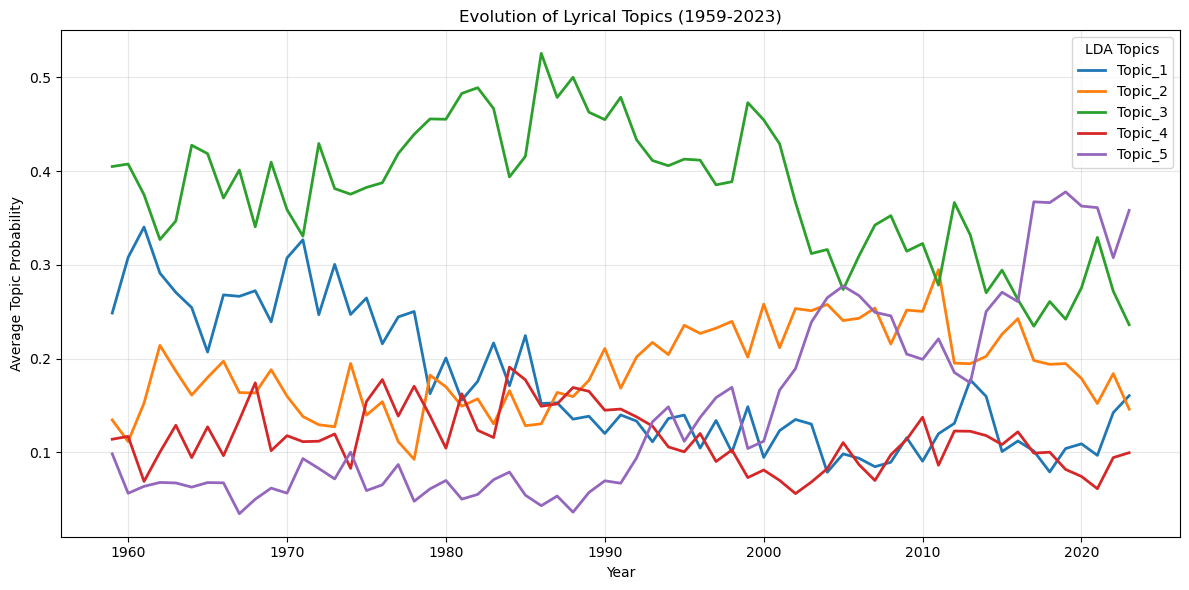

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

topic_columns = ["Topic_1", "Topic_2", "Topic_3", "Topic_4", "Topic_5"]

probability_sums = lda_results[topic_columns].sum(axis=1)

print("All probabilities sum to 1:", np.allclose(probability_sums, 1.0))

yearly_topics = lda_results.groupby("Year")[topic_columns].mean()

print("Number of years:", len(yearly_topics))
display(yearly_topics.head())

plt.figure(figsize=(12, 6))

for topic in topic_columns:
    plt.plot(yearly_topics.index, yearly_topics[topic], label=topic, linewidth=2)

plt.xlabel("Year")
plt.ylabel("Average Topic Probability")
plt.title("Evolution of Lyrical Topics (1959-2023)")
plt.legend(title="LDA Topics")
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig("LDA_01_Topic_Evolution.png", dpi=300, bbox_inches="tight")

plt.show()

yearly_topics.to_csv("LDA_Yearly_Topic_Trends.csv", encoding="utf-8-sig")

In [19]:
for topic_idx in range(5):

    print(f"\n========== Topic {topic_idx + 1} ==========")

    print("Keywords:")
    print(", ".join(refined_topic_words[topic_idx]))

    top_indices = np.argsort(lda_topics_refined[:, topic_idx])[-3:][::-1]

    for idx in top_indices:

        song = lda_df.iloc[idx]

        print("\nSong:", song["Song Title"])
        print("Year:", song["Year"])
        print("Rank:", song["Rank"])

        print("Topic Probability:", round(lda_topics_refined[idx, topic_idx], 3))

        print("Lyric Excerpt:")
        print(str(song["Clean Lyrics"])[:250])

    print("-" * 60)


========== Topic 1 ==========
Keywords:
night, little, dance, come, away, doo, let, home, light, like, eyes, woman

Song: Cotton Eye Joe
Year: 1995
Rank: 93
Topic Probability: 0.996
Lyric Excerpt:
if it hadn't been for cotton-eyed joe i'd been married long time ago where did you come from where did you go where did you come from cotton-eyed joe if it hadn't been for cotton-eyed joe i'd been married long time ago where did you come from where d

Song: Come Sail Away
Year: 1978
Rank: 56
Topic Probability: 0.995
Lyric Excerpt:
i'm sailing away set an open course for the virgin sea 'cause i've got to be free free to face the life that's ahead of me on board i'm the captain so climb aboard we'll search for tomorrow on every shore and i'll try oh lord i'll try to carry on i l

Song: Into The Night
Year: 2008
Rank: 98
Topic Probability: 0.995
Lyric Excerpt:
like a gift from the heavens it was easy to tell it was love from above that could save me from hell she had fire in her soul it was eas

In [20]:
for topic_idx in [2, 3]:

    print(f"\n========== Topic {topic_idx + 1} ==========")

    review_df = lda_df.copy()
    review_df["Topic Probability"] = lda_topics_refined[:, topic_idx]

    review_df = review_df.sort_values( "Topic Probability", ascending=False)

    review_df = review_df.drop_duplicates(subset=["Song Title", "Artist"])

    for _, song in review_df.head(5).iterrows():

        print("\nSong:", song["Song Title"])
        print("Artist:", song["Artist"])
        print("Year:", song["Year"])
        print("Topic Probability:", round(song["Topic Probability"], 3))

        print("Lyric Excerpt:")
        print(str(song["Clean Lyrics"])[:200])

    print("-" * 60)


========== Topic 3 ==========

Song: Doesn't Really Matter
Artist: Janet
Year: 2000
Topic Probability: 0.997
Lyric Excerpt:
doesn't matter doesn't matter doesn't matter at all doesn't matter what your friends are telling you doesn't matter what my family's saying too it just matters that i'm in love with you it only matter

Song: We Are The World
Artist: U.S.A. For Africa
Year: 1985
Topic Probability: 0.997
Lyric Excerpt:
there comes a time when we heed a certain call when the world must come together as one there are people dying and it's time to lend a hand to life the greatest gift of all we can't go on pretending d

Song: The Promise Of A New Day
Artist: Paula Abdul
Year: 1991
Topic Probability: 0.996
Lyric Excerpt:
eagle's calling and he's calling your name tides are turning bringing winds of change why do i feel this way the promise of a new day the promise the promise of a new day as through time the earth mov

Song: Differences
Artist: Ginuwine
Year: 2001
Topic Probability: 0.